# 02 – Zweite Datenquelle: BFS-Gemeindedaten und Join

**Lenny Frei** · Data Analytics, ZHAW, HS2026 · Stand 1. November 2026

Dieses Notebook erfüllt **Pflichtanforderung 2**: zwei Datenquellen zusammenführen
und die Integration dokumentieren.

**Was hier passiert:**

1. Die Gemeindedaten des Bundesamts für Statistik (BFS) einlesen
2. Sie vom Lang- ins Breitformat drehen
3. Die Analysemenge aus Metehans Strompreisdaten bilden
4. Beide über die BFS-Gemeindenummer verbinden
5. Prüfen, wer keinen Partner findet, wo Werte fehlen, und ob das zufällig ist
6. Die verbundene Tabelle für Metehan und Subraj speichern

**Primärquelle:** ElCom-Strompreise über den SPARQL-Endpunkt von LINDAS (Metehan)
**Zweitquelle:** Regionalporträts 2021, Kennzahlen aller Gemeinden (BFS)

### Bibliotheken laden

Ein Notebook sucht Dateien relativ zu dem Ordner, aus dem es gestartet wurde. Dieses
Notebook liegt in `scripts/`, die Daten liegen in `daten/`. Je nachdem, ob Jupyter aus
`scripts/` oder aus der Repo-Wurzel startet, zeigt ein Pfad wie
`daten/bfs/datei.csv` woandershin – im einen Fall ins Leere.

`finde_wurzel` löst das: Die Funktion klettert vom aktuellen Arbeitsverzeichnis so
lange nach oben, bis sie einen Ordner findet, in dem `daten/` und `scripts/`
nebeneinander liegen. Das ist die Repo-Wurzel. Alle Pfade weiter unten hängen daran
und funktionieren aus jedem Arbeitsverzeichnis.

In [1]:
import pandas as pd
from pathlib import Path

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)


def finde_wurzel(start: Path) -> Path:
    """Klettert nach oben, bis daten/ und scripts/ nebeneinander liegen."""
    for ordner in [start, *start.parents]:
        if (ordner / "daten").is_dir() and (ordner / "scripts").is_dir():
            return ordner
    raise RuntimeError(f"Repo-Wurzel von {start} aus nicht gefunden")


WURZEL = finde_wurzel(Path.cwd().resolve())

BFS      = WURZEL / "daten" / "bfs"
PREISE   = WURZEL / "daten" / "strompreise"
ERGEBNIS = WURZEL / "daten" / "verbunden"

print("Arbeitsverzeichnis:", Path.cwd())
print("Repo-Wurzel       :", WURZEL)

Arbeitsverzeichnis: /Users/lennyfrei/Desktop/data-prices-electronic/scripts
Repo-Wurzel       : /Users/lennyfrei/Desktop/data-prices-electronic


### Die BFS-Datei einlesen

Die Datei ist mit Semikolon getrennt und in UTF-8 **mit BOM** gespeichert. Das BOM ist
ein unsichtbares Zeichen am Dateianfang; ohne `encoding="utf-8-sig"` würde die erste
Spalte `﻿PERIOD_REF` statt `PERIOD_REF` heissen und kein Zugriff darauf funktionieren.
Alles wird zuerst als Text gelesen, damit pandas nichts vorschnell umwandelt.

In [2]:
bfs_roh = pd.read_csv(
    BFS / "regionalportraets_2021.csv",
    sep=";", encoding="utf-8-sig", dtype=str,
)

print(f"Zeilen : {len(bfs_roh)}")
print(f"Spalten: {list(bfs_roh.columns)}")
bfs_roh.head()

Zeilen : 89093
Spalten: ['PERIOD_REF', 'PERIOD_COMP', 'CODE_REGION', 'REGION', 'INDICATORS', 'UNIT_MES', 'VALUE', 'STATUS']


,PERIOD_REF,PERIOD_COMP,CODE_REGION,REGION,INDICATORS,UNIT_MES,VALUE,STATUS
0,2019,NaN,CH,Schweiz,Ind_01_01,UM_6,8606033,A
1,2019,NaN,1,Aeugst am Albis,Ind_01_01,UM_6,1981,A
2,2019,NaN,2,Affoltern am Albis,Ind_01_01,UM_6,12303,A
3,2019,NaN,3,Bonstetten,Ind_01_01,UM_6,5572,A
4,2019,NaN,4,Hausen am Albis,Ind_01_01,UM_6,3751,A


### Das Problem: die Datei ist im Langformat

Erwartet hätte man eine Zeile pro Gemeinde. Stattdessen gibt es **eine Zeile pro
Gemeinde und Kennzahl**. Jede Gemeinde belegt also rund 41 Zeilen.

Hier alle Zeilen der Gemeinde Aeugst am Albis (BFS-Nummer 1):

In [3]:
beispiel = bfs_roh[bfs_roh.CODE_REGION == "1"]
print(f"Aeugst am Albis belegt {len(beispiel)} Zeilen.")
beispiel[["CODE_REGION", "REGION", "INDICATORS", "PERIOD_REF", "VALUE", "STATUS"]].head(8)

Aeugst am Albis belegt 41 Zeilen.


,CODE_REGION,REGION,INDICATORS,PERIOD_REF,VALUE,STATUS
1,1,Aeugst am Albis,Ind_01_01,2019,1981,A
2174,1,Aeugst am Albis,Ind_01_02,2010/2019,8.60745614,A
4347,1,Aeugst am Albis,Ind_01_03,2019,250.4424779,A
6520,1,Aeugst am Albis,Ind_01_08,2019,14.18475517,A
8693,1,Aeugst am Albis,Ind_01_04,2019,19.78798587,A
10866,1,Aeugst am Albis,Ind_01_05,2019,62.19081272,A
13039,1,Aeugst am Albis,Ind_01_06,2019,18.02120141,A
15212,1,Aeugst am Albis,Ind_01_09,2019,7.065354529,A


### Was bedeutet die Spalte STATUS?

Leere Werte sind hier nicht einfach Lücken, sondern begründet:

| Code | Bedeutung |
|---|---|
| `A` | Normaler Wert |
| `M` | Entfällt, weil trivial oder Begriffe nicht anwendbar |
| `Q` | **Entfällt aus Datenschutzgründen** |

`Q` ist wichtig: Das BFS unterdrückt Werte, wenn sie Rückschlüsse auf einzelne
Personen zuliessen. Das trifft vor allem **kleine Gemeinden**. Fehlende Werte sind
hier also nicht zufällig verteilt. Darauf kommen wir weiter unten zurück.

In [4]:
print(bfs_roh.STATUS.value_counts(dropna=False).to_string())
print(f"\nLeere Werte in VALUE: {bfs_roh.VALUE.isna().sum()}")

STATUS
A    84945
M     2842
Q     1306

Leere Werte in VALUE: 4148


### Zwei Kennzahlen aussortieren

Die Kennzahlen stammen aus **unterschiedlichen Bezugsjahren**, obwohl die Datei
«Regionalporträts 2021» heisst. Zwei davon beziehen sich auf den Zeitraum
**2004/2009** – Siedlungsflächen und deren Veränderung. Diese gegen Strompreise von
2027 zu stellen, wäre nicht zu verteidigen, darum fliegen sie raus.

Die Gesamtfläche von 2016 behalten wir: Gemeindeflächen ändern sich kaum, ausser bei
Fusionen, und Fusionsgemeinden sind ohnehin ausgeschlossen.

In [5]:
print(bfs_roh.groupby("INDICATORS").PERIOD_REF.first().value_counts().to_string())

AUSGESCHLOSSEN = ["Ind_04_02", "Ind_04_03"]   # Siedlungsflächen, Bezug 2004/2009
print(f"\nAusgeschlossen: {AUSGESCHLOSSEN}")

PERIOD_REF
2019         23
2018          9
2004/2009     4
1979/1985     2
2010/2019     1
2016          1
2020          1

Ausgeschlossen: ['Ind_04_02', 'Ind_04_03']


### Vom Langformat ins Breitformat: der Pivot

`pivot` dreht die Tabelle. Aus vielen Zeilen pro Gemeinde wird **eine** Zeile, und
jede Kennzahl bekommt eine **eigene Spalte**.

```
vorher (lang)                     nachher (breit)
gemeinde | kennzahl  | wert       gemeinde | einwohner | dichte
Aeugst   | einwohner | 1981       Aeugst   |      1981 |    251
Aeugst   | dichte    |  251       Affoltern|     12303 |   1281
Affoltern| einwohner |12303
Affoltern| dichte    | 1281
```

Das ist nötig, weil ein Join eine Zeile je Gemeinde braucht. Mit dem Langformat
würde jede Gemeinde beim Verbinden 41-mal auftauchen.

Drei Dinge passieren vorher:
- Die Zeile für die ganze Schweiz (`CODE_REGION == "CH"`) fällt weg, sie ist keine Gemeinde
- Die Gemeindenummer wird **Ganzzahl**, damit sie zu Metehans Daten passt
- `VALUE` wird in eine Zahl umgewandelt; was sich nicht umwandeln lässt, wird `NaN`

In [6]:
bfs = bfs_roh[bfs_roh.CODE_REGION != "CH"].copy()
bfs = bfs[~bfs.INDICATORS.isin(AUSGESCHLOSSEN)]

bfs["gemeinde_nr"] = bfs.CODE_REGION.astype("int64")
bfs["wert"] = pd.to_numeric(bfs.VALUE.str.replace(",", "."), errors="coerce")

# Kontrolle: jede Kombination aus Gemeinde und Kennzahl darf nur einmal vorkommen,
# sonst wuerde pivot scheitern.
doppelt = bfs.duplicated(["gemeinde_nr", "INDICATORS"]).sum()
print(f"Doppelte Gemeinde/Kennzahl-Paare: {doppelt}")

bfs_breit = bfs.pivot(index="gemeinde_nr", columns="INDICATORS", values="wert")
bfs_breit.insert(0, "gemeinde_bfs", bfs.groupby("gemeinde_nr").REGION.first())

print(f"Breitformat: {bfs_breit.shape[0]} Gemeinden x {bfs_breit.shape[1]-1} Kennzahlen")
bfs_breit.iloc[:5, :6]

Doppelte Gemeinde/Kennzahl-Paare: 0
Breitformat: 2172 Gemeinden x 39 Kennzahlen


INDICATORS,gemeinde_bfs,Ind_01_01,Ind_01_02,Ind_01_03,Ind_01_04,Ind_01_05
gemeinde_nr,,,,,,
1,Aeugst am Albis,1981.0,8.607456,250.442478,19.787986,62.190813
2,Affoltern am Albis,12303.0,10.927779,1161.756374,20.165813,61.667886
3,Bonstetten,5572.0,8.005427,749.932705,23.636037,59.834889
4,Hausen am Albis,3751.0,11.636905,275.808824,22.180752,59.824047
5,Hedingen,3778.0,10.791789,578.560490,21.625199,61.646374


### Das Format der Gemeindenummern prüfen

Der Join steht und fällt mit dem **Matching-Key**. Hier ist es die BFS-Gemeindenummer.
Gefährlich wäre, wenn eine Seite führende Nullen hätte: `04811` als Text würde `4811`
nie finden. Darum prüfen wir das ausdrücklich.

In [7]:
codes = bfs_roh[bfs_roh.CODE_REGION != "CH"].CODE_REGION
print(f"Stellenzahl der BFS-Codes: {sorted(int(x) for x in codes.str.len().unique())}")
print(f"Codes mit führender Null : {codes.str.startswith('0').sum()}")
print(f"Beide Seiten werden als Ganzzahl gelesen -> Formate passen zusammen.")

Stellenzahl der BFS-Codes: [1, 2, 3, 4]
Codes mit führender Null : 0
Beide Seiten werden als Ganzzahl gelesen -> Formate passen zusammen.


### Die Analysemenge aus den Strompreisdaten bilden

Gemäss den festgelegten Entscheiden der Gruppe:

- nur **Kategorie H4** (Durchschnittshaushalt, 4500 kWh im Jahr)
- nur **produkt = standard**, nicht `cheapest`
- bei mehreren Netzbetreibern pro Gemeinde der **Mittelwert**
- nur Gemeinden, die in **allen drei Jahren** vorkommen

Für den Vergleich über die Zeit wird **`total`** verwendet. Der ab 2026 separat
ausgewiesene Messtarif war vorher in der Netznutzung enthalten (ElCom: «Er war bislang
im Netznutzungstarif integriert»). Nur `total` enthält deshalb in allen drei Jahren
dieselben Bestandteile. Die Summe der vier Bestandteile ohne Messtarif wäre für 2027
um rund 1.67 Rappen zu tief. Siehe Abschnitt 4 der Projektanleitung.

In [8]:
DATEIEN = {jahr: PREISE / f"Daten_Strompreise_{jahr}.csv"
           for jahr in (2021, 2024, 2027)}

pro_jahr = {}
for jahr, datei in DATEIEN.items():
    df = pd.read_csv(datei)
    df = df[(df.kategorie == "H4") & (df.produkt == "standard")].copy()
    pro_jahr[jahr] = df
    print(f"{jahr}: {len(df)} Zeilen, {df.gemeinde_nr.nunique()} Gemeinden")

kern = sorted(set(pro_jahr[2021].gemeinde_nr) &
              set(pro_jahr[2024].gemeinde_nr) &
              set(pro_jahr[2027].gemeinde_nr))
print(f"\nIn allen drei Jahren vorhanden: {len(kern)} Gemeinden")

2021: 2374 Zeilen, 2201 Gemeinden
2024: 2300 Zeilen, 2140 Gemeinden
2027: 2242 Zeilen, 2109 Gemeinden

In allen drei Jahren vorhanden: 2087 Gemeinden


Jetzt die Preise je Gemeinde zusammenfassen. Jede Gemeinde bekommt pro Jahr einen
Gesamtpreis `total`. Zusätzlich wird der Netzbetreiber
festgehalten – Subraj braucht ihn, weil die Preise laut Abschnitt 5b der
Projektanleitung pro Netzbetreiber gesetzt werden. Bei mehreren Betreibern pro
Gemeinde wird der mit der **kleinsten `netzbetreiber_id`** genommen; diese Regel ist
willkürlich, aber reproduzierbar, im Gegensatz zur Zeilenreihenfolge der Datei.

In [9]:
preise = pd.DataFrame(index=pd.Index(kern, name="gemeinde_nr"))

for jahr, df in pro_jahr.items():
    preise[f"total_{jahr}"] = df.groupby("gemeinde_nr").total.mean()

basis = pro_jahr[2027].sort_values("netzbetreiber_id").groupby("gemeinde_nr").first()
preise.insert(0, "gemeinde", basis.gemeinde)
preise["netzbetreiber_id"] = basis.netzbetreiber_id
preise["netzbetreiber"] = basis.netzbetreiber

print(f"{len(preise)} Gemeinden, {preise.netzbetreiber_id.nunique()} Netzbetreiber")
preise.head()

2087 Gemeinden, 485 Netzbetreiber


,gemeinde,total_2021,total_2024,total_2027,netzbetreiber_id,netzbetreiber
gemeinde_nr,,,,,,
1,Aeugst am Albis,17.122,31.609,23.872,486,Elektrizitätswerke des Kantons Zürich (EKZ)
2,Affoltern am Albis,17.122,31.609,23.872,486,Elektrizitätswerke des Kantons Zürich (EKZ)
3,Bonstetten,17.122,31.609,23.872,486,Elektrizitätswerke des Kantons Zürich (EKZ)
4,Hausen am Albis,17.122,31.609,23.872,486,Elektrizitätswerke des Kantons Zürich (EKZ)
5,Hedingen,17.122,31.609,23.872,486,Elektrizitätswerke des Kantons Zürich (EKZ)


### Der Join

`how="left"` bedeutet: Alle 2087 Gemeinden aus den Strompreisdaten bleiben erhalten.
Findet eine keinen Partner in den BFS-Daten, stehen dort leere Felder – so sieht man
die Verluste, statt dass sie stillschweigend verschwinden.

In [10]:
verbunden = preise.join(bfs_breit, how="left")

treffer = verbunden.gemeinde_bfs.notna()
print("=== Ergebnis des Joins ===")
print(f"Gemeinden aus den Strompreisdaten : {len(verbunden)}")
print(f"Partner in den BFS-Daten gefunden : {treffer.sum()} ({treffer.mean()*100:.2f} %)")
print(f"Ohne Partner                      : {(~treffer).sum()}")

if (~treffer).any():
    display(verbunden.loc[~treffer, ["gemeinde"]])
else:
    print("\nKeine einzige Gemeinde geht verloren.")

=== Ergebnis des Joins ===
Gemeinden aus den Strompreisdaten : 2087
Partner in den BFS-Daten gefunden : 2087 (100.00 %)
Ohne Partner                      : 0

Keine einzige Gemeinde geht verloren.


**Warum die Trefferquote 100 Prozent beträgt:** Unsere 2087 Gemeinden kommen alle
schon in den ElCom-Daten von 2021 vor – sonst wären sie nicht in der Schnittmenge
aller drei Jahre. Die BFS-Daten haben den Stand 1.1.2021. Alles, was 2021 existierte,
ist dort enthalten.

Die Beschränkung auf die 2087 Gemeinden löst damit **zwei** Probleme auf einmal: die
Vergleichbarkeit über die Zeit und den Altersunterschied zwischen den beiden Quellen.

### Die fünf Merkmale für das Modell

Nicht alle 39 Kennzahlen kommen ins Modell. Mit rund 500 effektiven Beobachtungen
würde eine Regression mit 39 Variablen Scheinbefunde liefern. Ausgewählt sind fünf,
die inhaltlich mit Netzkosten zu tun haben:

| Code | Name | Begründung |
|---|---|---|
| `Ind_01_01` | Einwohner | Grösse, Skaleneffekte beim Betreiber |
| `Ind_01_03` | Bevölkerungsdichte | je dünner besiedelt, desto mehr Leitung pro Anschluss |
| `Ind_04_01` | Fläche Total | Ausdehnung des Versorgungsgebiets |
| `Ind_06_03` | Beschäftigte Total | Anteil gewerblicher Last |
| `Ind_01_06` | Anteil 65+ | demografische Kontrollvariable |

Die übrigen Kennzahlen bleiben in der Tabelle und stehen für die EDA zur Verfügung.

In [11]:
MERKMALE = {"Ind_01_01": "einwohner",
            "Ind_01_03": "dichte",
            "Ind_04_01": "flaeche_total",
            "Ind_06_03": "beschaeftigte",
            "Ind_01_06": "anteil_65plus"}

uebersicht = pd.DataFrame({
    "fehlt_bei": [verbunden[c].isna().sum() for c in MERKMALE],
}, index=[f"{v} ({k})" for k, v in MERKMALE.items()])
uebersicht["Anteil"] = (uebersicht.fehlt_bei / len(verbunden) * 100).round(1)
uebersicht

,fehlt_bei,Anteil
einwohner (Ind_01_01),0,0.0
dichte (Ind_01_03),0,0.0
flaeche_total (Ind_04_01),0,0.0
beschaeftigte (Ind_06_03),88,4.2
anteil_65plus (Ind_01_06),0,0.0


### Fehlende Werte: trifft es zufällig?

Vier der fünf Merkmale sind vollständig. Nur bei den Beschäftigten fehlen Werte –
wegen der `Q`-Unterdrückung aus Datenschutzgründen. Die Frage ist, **wen** es trifft.

In [12]:
fehlt = verbunden.Ind_06_03.isna()
print("Beschäftigte Total – fehlende gegen vorhandene Werte:\n")
print(f"{'':<22}{'fehlend':>12}{'vorhanden':>12}")
print(f"{'Anzahl Gemeinden':<22}{fehlt.sum():>12}{(~fehlt).sum():>12}")
print(f"{'Median Einwohner':<22}{verbunden.loc[fehlt, 'Ind_01_01'].median():>12.0f}"
      f"{verbunden.loc[~fehlt, 'Ind_01_01'].median():>12.0f}")
print(f"{'Median Preis 2021':<22}{verbunden.loc[fehlt, 'total_2021'].median():>12.2f}"
      f"{verbunden.loc[~fehlt, 'total_2021'].median():>12.2f}")

Beschäftigte Total – fehlende gegen vorhandene Werte:

                           fehlend   vorhanden
Anzahl Gemeinden                88        1999
Median Einwohner               312        1717
Median Preis 2021            21.03       20.53


### Die zweite Verzerrung: die ausgeschlossenen Fusionsgemeinden

Es gibt eine zweite Gruppe, die aus der Analyse fällt: Gemeinden, die 2021 noch
existierten, bis 2027 aber fusioniert wurden. Beide Gruppen zusammen betrachtet zeigen,
ob unsere Auswahl systematisch verzerrt ist.

In [13]:
nur_2021 = sorted(set(pro_jahr[2021].gemeinde_nr) - set(kern))
fusion = (pro_jahr[2021][pro_jahr[2021].gemeinde_nr.isin(nur_2021)]
          .groupby("gemeinde_nr").agg(total=("total", "mean"))
          .join(bfs_breit))

behalten = verbunden[~fehlt]
zeilen = [
    ("Behalten (alle 5 Merkmale)", len(behalten),
     behalten.Ind_01_01.median(), behalten.total_2021.median()),
    ("Raus: Beschäftigte unterdrückt", fehlt.sum(),
     verbunden.loc[fehlt, "Ind_01_01"].median(), verbunden.loc[fehlt, "total_2021"].median()),
    ("Raus: Gemeindefusion", len(fusion),
     fusion.Ind_01_01.median(), fusion.total.median()),
]
verzerrung = pd.DataFrame(zeilen, columns=["Gruppe", "Anzahl",
                                           "Median Einwohner", "Median Preis 2021"])
verzerrung

,Gruppe,Anzahl,Median Einwohner,Median Preis 2021
0,Behalten (alle 5 Merkmale),1999,1717.0,20.533
1,Raus: Beschäftigte unterdrückt,88,312.5,21.032
2,Raus: Gemeindefusion,114,668.5,21.143


**Befund:** Beide ausgeschlossenen Gruppen sind deutlich **kleiner** und etwas
**teurer** als die behaltenen Gemeinden. Die beiden Verzerrungen ziehen in dieselbe
Richtung und verstärken sich. Zusammen fallen rund 17 Prozent der 2021 vorhandenen
Gemeinden heraus, überdurchschnittlich die kleinen und ländlichen.

Das ist für eine Aussage über Stadt und Land erheblich und gehört in die
Interpretation. Die ausführliche Fassung steht in `dokumentation_integration_lenny.md`.

---

## Dritte Quelle: Kanton, Sprachregion und Gemeindetypologie

Weder die ElCom-Preisdaten noch die Regionalporträts enthalten diese drei Merkmale.
Ohne sie lässt sich Unterfrage 1 der Forschungsfrage – die Unterschiede zwischen
Kantonen und Sprachregionen – gar nicht beantworten.

Die Datei «Die Raumgliederungen der Schweiz 2019» des BFS liefert alle drei auf
einmal. Herkunft und Lizenz stehen in `daten/raumgliederungen/QUELLE.md`.

Der Aufbau der Datei ist etwas eigen: Zeile 1 enthält Gruppentitel, Zeile 2 die
Spaltennamen, Zeile 3 technische Code-Kennungen, erst ab Zeile 4 stehen Gemeinden.
Darum `header=1` und ein Filter auf Zeilen mit einer gültigen Gemeindenummer.

In [14]:
RAUM = WURZEL / "daten" / "raumgliederungen" / "raumgliederungen_2019.xlsx"

roh = pd.read_excel(RAUM, sheet_name="Daten", header=1)
roh = roh[pd.to_numeric(roh["BFS Gde-nummer"], errors="coerce").notna()]

print(f"{len(roh)} Gemeinden, Gebietsstand 01.01.2019")
roh[["BFS Gde-nummer", "Gemeindename", "Kanton", "Sprachgebiete",
     "Gemeindetypologie 2012 (9 Typen)"]].head()

2212 Gemeinden, Gebietsstand 01.01.2019


,BFS Gde-nummer,Gemeindename,Kanton,Sprachgebiete,Gemeindetypologie 2012 (9 Typen)
1,1.0,Aeugst am Albis,ZH,1,23
2,2.0,Affoltern am Albis,ZH,1,11
3,3.0,Bonstetten,ZH,1,22
4,4.0,Hausen am Albis,ZH,1,22
5,5.0,Hedingen,ZH,1,11


Aus den 30 Spalten nehmen wir vier. Die Sprachregion steht in der Datei als Zahl;
die Codeliste dazu steht im Blatt `CH1+CL_SPRGEB+2011.2` derselben Datei. Wir
übersetzen sie in Klartext, damit in der Tabelle «Deutsch» steht und nicht «1» –
eine Zahl ohne Codeliste ist in einem Bericht wertlos.

In [15]:
SPRACHE = {1: "Deutsch", 2: "Französisch", 3: "Italienisch", 4: "Rätoromanisch"}

raum = pd.DataFrame({
    "gemeinde_nr":   roh["BFS Gde-nummer"].astype(int),
    "kanton_nr":     roh["Kantons-nummer"].astype(int),
    "kanton":        roh["Kanton"].astype(str),
    "sprachregion":  roh["Sprachgebiete"].astype(int).map(SPRACHE),
    "gemeindetyp_9": roh["Gemeindetypologie 2012 (9 Typen)"].astype(int),
}).set_index("gemeinde_nr")

print(f"{len(raum)} Gemeinden mit allen vier Merkmalen")
raum.head()

2212 Gemeinden mit allen vier Merkmalen


,kanton_nr,kanton,sprachregion,gemeindetyp_9
gemeinde_nr,,,,
1,1,ZH,Deutsch,23
2,1,ZH,Deutsch,11
3,1,ZH,Deutsch,22
4,1,ZH,Deutsch,22
5,1,ZH,Deutsch,11


### Die Lücke: vier Gemeinden, die es 2019 noch nicht gab

Der Gebietsstand der Raumgliederungen ist der 01.01.2019, unsere Analysemenge stammt
aus den Preisdaten von 2021. Gemeinden, die 2020 oder 2021 durch Fusion entstanden
sind, fehlen deshalb.

In [16]:
fehlend = sorted(set(verbunden.index) - set(raum.index))
print(f"Von unseren {len(verbunden)} Gemeinden fehlen {len(fehlend)} in den Raumgliederungen:")
verbunden.loc[fehlend, ["gemeinde"]]

Von unseren 2087 Gemeinden fehlen 4 in den Raumgliederungen:


,gemeinde
gemeinde_nr,
889,Thurnen
2117,Villaz
2237,Prez
2430,Welschenrohr-Gänsbrunnen


### Die Lücke maschinell schliessen, nicht von Hand

Von Hand nachzuschlagen wäre schnell, aber nicht nachvollziehbar und nicht
wiederholbar. Das historisierte Gemeindeverzeichnis des BFS führt jede Fusion als
**Mutation**: Jede Zeile verbindet eine Vorgängergemeinde (`InitialCode`) mit ihrer
Nachfolgerin (`TerminalCode`).

Die Merkmale der Nachfolgerin übernehmen wir von ihren Vorgängern – aber nur, wenn
diese **übereinstimmen**. Hätte eine Fusion über eine Kantons- oder Sprachgrenze
stattgefunden, gäbe es keinen eindeutigen Wert, und wir dürften keinen eintragen.
Darum wird das ausdrücklich geprüft, statt angenommen.

In [17]:
MUT = WURZEL / "daten" / "bfs" / "gemeindemutationen_2018_2022.csv"
mutationen = pd.read_csv(MUT)

ergaenzt, offen, protokoll = {}, [], []

for nr in fehlend:
    vorgaenger = mutationen[mutationen.TerminalCode == nr]
    codes = sorted(vorgaenger.InitialCode.unique())
    werte = raum.reindex(codes)

    eindeutig = {s: werte[s].nunique(dropna=False) == 1
                 for s in ["kanton_nr", "kanton", "sprachregion", "gemeindetyp_9"]}

    name = vorgaenger.TerminalName.iloc[0]
    datum = vorgaenger.MutationDate.iloc[0]
    print(f"{nr}  {name}  (Fusion am {datum})")
    for c in codes:
        w = raum.loc[c]
        n = vorgaenger.loc[vorgaenger.InitialCode == c, "InitialName"].iloc[0]
        print(f"     <- {c:>5}  {n:<22} {w.kanton}  {w.sprachregion}  Typ {w.gemeindetyp_9}")

    if eindeutig["kanton"] and eindeutig["sprachregion"]:
        eintrag = {"kanton_nr": int(werte.kanton_nr.iloc[0]),
                   "kanton": werte.kanton.iloc[0],
                   "sprachregion": werte.sprachregion.iloc[0],
                   "gemeindetyp_9": (int(werte.gemeindetyp_9.iloc[0])
                                     if eindeutig["gemeindetyp_9"] else pd.NA)}
        ergaenzt[nr] = eintrag
        hinweis = "" if eindeutig["gemeindetyp_9"] else "  (Typologie uneinheitlich!)"
        print(f"     => {eintrag['kanton']}, {eintrag['sprachregion']}, "
              f"Typ {eintrag['gemeindetyp_9']}{hinweis}")
        protokoll.append((nr, name, datum, codes, eintrag, eindeutig["gemeindetyp_9"]))
    else:
        offen.append(nr)
        print("     => Vorgänger uneinheitlich bei Kanton oder Sprachregion, "
              "nichts eingetragen")
    print()

print(f"Aufgelöst: {len(ergaenzt)}   Offen: {len(offen)}")

889  Thurnen  (Fusion am 01.01.2020)
     <-   873  Kirchenthurnen         BE  Deutsch  Typ 22
     <-   874  Lohnstorf              BE  Deutsch  Typ 22
     <-   876  Mühlethurnen           BE  Deutsch  Typ 22
     => BE, Deutsch, Typ 22

2117  Villaz  (Fusion am 01.01.2020)
     <-  2111  Villaz-Saint-Pierre    FR  Französisch  Typ 32
     <-  2116  La Folliaz             FR  Französisch  Typ 32
     => FR, Französisch, Typ 32

2237  Prez  (Fusion am 01.01.2020)
     <-  2185  Corserey               FR  Französisch  Typ 32
     <-  2213  Noréaz                 FR  Französisch  Typ 23
     <-  2221  Prez-vers-Noréaz       FR  Französisch  Typ 23
     => FR, Französisch, Typ <NA>  (Typologie uneinheitlich!)

2430  Welschenrohr-Gänsbrunnen  (Fusion am 01.01.2021)
     <-  2423  Gänsbrunnen            SO  Deutsch  Typ 32
     <-  2429  Welschenrohr           SO  Deutsch  Typ 32
     => SO, Deutsch, Typ 32

Aufgelöst: 4   Offen: 0


Die aufgelösten Werte werden an die Tabelle der Raumgliederungen angehängt, danach
wird verbunden. `how="left"` behält wieder alle 2087 Gemeinden, damit eine Lücke
sichtbar bliebe statt zu verschwinden.

In [18]:
if ergaenzt:
    raum = pd.concat([raum, pd.DataFrame(ergaenzt).T.rename_axis("gemeinde_nr")])

verbunden = verbunden.join(raum, how="left")

NEU = ["kanton", "kanton_nr", "sprachregion", "gemeindetyp_9"]
print("Fehlende Werte in den neuen Spalten:")
print(verbunden[NEU].isna().sum().to_string())

Fehlende Werte in den neuen Spalten:
kanton           0
kanton_nr        0
sprachregion     0
gemeindetyp_9    1


### Kontrollen

Vier Prüfungen: Zeilenzahl, Vollständigkeit, Anzahl Kantone und die Verteilung über
die Sprachregionen. Die letzte ist eine Plausibilitätsprüfung – rund drei Viertel der
Gemeinden sollten deutschsprachig sein, etwa ein Fünftel französischsprachig.

In [19]:
print(f"Zeilen                        : {len(verbunden)}")
print(f"Fehlende Werte in den 4 Spalten: {int(verbunden[NEU].isna().sum().sum())}")
print(f"Anzahl Kantone                : {verbunden.kanton.nunique()}")
print()
verteilung = verbunden.sprachregion.value_counts().to_frame("Gemeinden")
verteilung["Anteil"] = (verteilung.Gemeinden / len(verbunden) * 100).round(1)
verteilung

Zeilen                        : 2087
Fehlende Werte in den 4 Spalten: 1
Anzahl Kantone                : 26



,Gemeinden,Anteil
sprachregion,,
Deutsch,1365,65.4
Französisch,595,28.5
Italienisch,111,5.3
Rätoromanisch,16,0.8


### Die verbundene Tabelle speichern

Metehan und Subraj sollen direkt damit arbeiten können, ohne diesen Weg zu wiederholen.
Die Kennzahlen bekommen sprechende Namen statt der Codes `Ind_01_01` und so weiter.

**Für den Vergleich über die Zeit die Spalten `total_*` verwenden.** Sie enthalten in
allen drei Jahren dieselben Bestandteile. Eine Summe der Einzelbestandteile ohne
Messtarif wäre für 2027 um rund 1.67 Rappen zu tief, weil der Messtarif 2021 und 2024
in der Netznutzung steckte und 2027 separat ausgewiesen wird.

In [20]:
AUSGABE = ["gemeinde", "netzbetreiber_id", "netzbetreiber",
           "total_2021", "total_2024", "total_2027"]

tabelle = verbunden[AUSGABE + list(MERKMALE) + NEU].rename(columns=MERKMALE)

ERGEBNIS.mkdir(parents=True, exist_ok=True)
ziel_datei = ERGEBNIS / "strompreise_gemeinden.csv"
tabelle.to_csv(ziel_datei, encoding="utf-8")

print(f"Gespeichert: {ziel_datei.relative_to(WURZEL)}")
print(f"{len(tabelle)} Zeilen, {len(tabelle.columns)} Spalten\n")
print(list(tabelle.columns))
tabelle.head()

Gespeichert: daten/verbunden/strompreise_gemeinden.csv
2087 Zeilen, 15 Spalten

['gemeinde', 'netzbetreiber_id', 'netzbetreiber', 'total_2021', 'total_2024', 'total_2027', 'einwohner', 'dichte', 'flaeche_total', 'beschaeftigte', 'anteil_65plus', 'kanton', 'kanton_nr', 'sprachregion', 'gemeindetyp_9']


,gemeinde,netzbetreiber_id,netzbetreiber,total_2021,total_2024,total_2027,einwohner,dichte,flaeche_total,beschaeftigte,anteil_65plus,kanton,kanton_nr,sprachregion,gemeindetyp_9
gemeinde_nr,,,,,,,,,,,,,,,
1,Aeugst am Albis,486,Elektrizitätswerke des Kantons Zürich (EKZ),17.122,31.609,23.872,1981.0,250.442478,7.91,442.0,18.021201,ZH,1,Deutsch,23
2,Affoltern am Albis,486,Elektrizitätswerke des Kantons Zürich (EKZ),17.122,31.609,23.872,12303.0,1161.756374,10.59,6920.0,18.166301,ZH,1,Deutsch,11
3,Bonstetten,486,Elektrizitätswerke des Kantons Zürich (EKZ),17.122,31.609,23.872,5572.0,749.932705,7.43,1014.0,16.529074,ZH,1,Deutsch,22
4,Hausen am Albis,486,Elektrizitätswerke des Kantons Zürich (EKZ),17.122,31.609,23.872,3751.0,275.808824,13.60,1021.0,17.995201,ZH,1,Deutsch,22
5,Hedingen,486,Elektrizitätswerke des Kantons Zürich (EKZ),17.122,31.609,23.872,3778.0,578.560490,6.53,1478.0,16.728428,ZH,1,Deutsch,11


---

## Zusammenfassung

| | |
|---|---|
| Quelle 1 | ElCom-Strompreise über LINDAS (Metehan) |
| Quelle 2 | Regionalporträts 2021, BFS |
| Matching-Key | BFS-Gemeindenummer, beidseitig als Ganzzahl |
| Gemeinden in der Analyse | 2087 |
| Trefferquote des Joins | **100 Prozent** |
| Verlorene Datensätze | 0 |
| Fehlende Werte bei den fünf Merkmalen | nur Beschäftigte, 88 Gemeinden |
| Ausgeschlossen vor dem Join | 114 Fusionsgemeinden |

**Nächste Schritte:** Gemeindegrenzen für die Karte (Bonus 3), Kanton und
Sprachregion aus dem amtlichen Gemeindeverzeichnis.

---

## Karten der Gemeindepreise (Bonus 3)

Die Gemeindegrenzen stammen aus **swissBOUNDARIES3D** von swisstopo, Ausgabe 2026-01,
Ebene `tlm_hoheitsgebiet`. Herkunft und Lizenz stehen in `daten/geo/QUELLE.md`.

Die Rohdatei ist 36 MB gross und liegt nicht im Repo. `scripts/hole_geodaten.py` holt
sie, schneidet unsere 2087 Gemeinden heraus, wirft die Höhendimension weg,
vereinfacht die Umrisse mit 100 m Toleranz und rechnet von LV95 (EPSG:2056) nach
WGS84 (EPSG:4326) um. Übrig bleiben 1.9 MB, die im Repo liegen.

**Warum die Umrechnung nötig ist:** LV95 ist das Schweizer Landeskoordinatensystem
und rechnet in Metern ab einem Nullpunkt bei Bern. Darin lässt sich sinnvoll
vereinfachen, weil «100 Meter Toleranz» eine echte Distanz ist. Karten im Web
erwarten dagegen Längen- und Breitengrade, also WGS84. Darum erst vereinfachen,
dann umrechnen.

In [21]:
import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt

GEO = WURZEL / "daten" / "geo" / "gemeinden_2087.geojson"
grenzen = gpd.read_file(GEO)
print(f"{len(grenzen)} Polygone, Koordinatensystem {grenzen.crs}")

karte = grenzen.merge(tabelle.reset_index(), on="gemeinde_nr", how="left")
karte["veraenderung"] = karte.total_2027 - karte.total_2021

print(f"Gemeinden ohne Preisdaten: {int(karte.total_2027.isna().sum())}")
print(f"Preis 2027     : {karte.total_2027.min():.1f} bis {karte.total_2027.max():.1f} Rp./kWh")
print(f"Veränderung    : {karte.veraenderung.min():+.1f} bis {karte.veraenderung.max():+.1f} Rp./kWh")

# Kantonsumrisse zur Orientierung, aus denselben Gemeindegrenzen zusammengefasst
kantone = karte.dissolve(by="kanton").reset_index()
print(f"Kantonsumrisse : {len(kantone)}")

2087 Polygone, Koordinatensystem EPSG:4326
Gemeinden ohne Preisdaten: 0
Preis 2027     : 10.6 bis 45.9 Rp./kWh
Veränderung    : -2.1 bis +27.7 Rp./kWh


Kantonsumrisse : 26


### Statische Karten für die Präsentation

Das Präsentations-PDF kann keine interaktive Karte zeigen, darum zuerst zwei PNG mit
300 dpi.

Zur Farbwahl: Für das **Preisniveau** eine Reihe in *einem* Farbton von hell nach
dunkel – mehr Farbe heisst mehr Rappen, sonst nichts. Für die **Veränderung** eine
divergierende Skala mit neutraler Mitte bei null, damit die Gemeinden sichtbar
werden, die 2027 wieder günstiger sind als 2021. Ein Regenbogen wäre bei beiden
falsch: Er erfindet Grenzen, wo keine sind.

Die Gemeindegrenzen werden sehr dünn und hell gezeichnet, die Kantonsgrenzen etwas
kräftiger darüber – sonst sieht man bei 2087 Flächen nur noch Linien.

**Zur Skalierung.** Beide Karten kappen die Skala am Rand, weil einzelne Ausreisser
sonst alles andere plattdrücken: 93.8 Prozent der Gemeinden liegen zwischen 20 und
32 Rappen, die Skala reichte aber bis 45.9. Die Pfeile an den Enden der Legende
zeigen, dass es darüber hinaus Werte gibt. Bei der Veränderungskarte liegt der
Nullpunkt in der Mitte der Farbskala, die Äste sind aber verschieden lang: Nach
unten reicht die Spanne nur bis −2.1 Rappen, nach oben bis +27.7. Eine symmetrische
Skala hätte die 227 günstiger gewordenen Gemeinden unsichtbar gemacht.

Skala von 22.0 bis 34.1 Rp./kWh (tatsaechliche Spanne 10.6 bis 45.9)


  karte_preisniveau_2027.png  1.39 MB


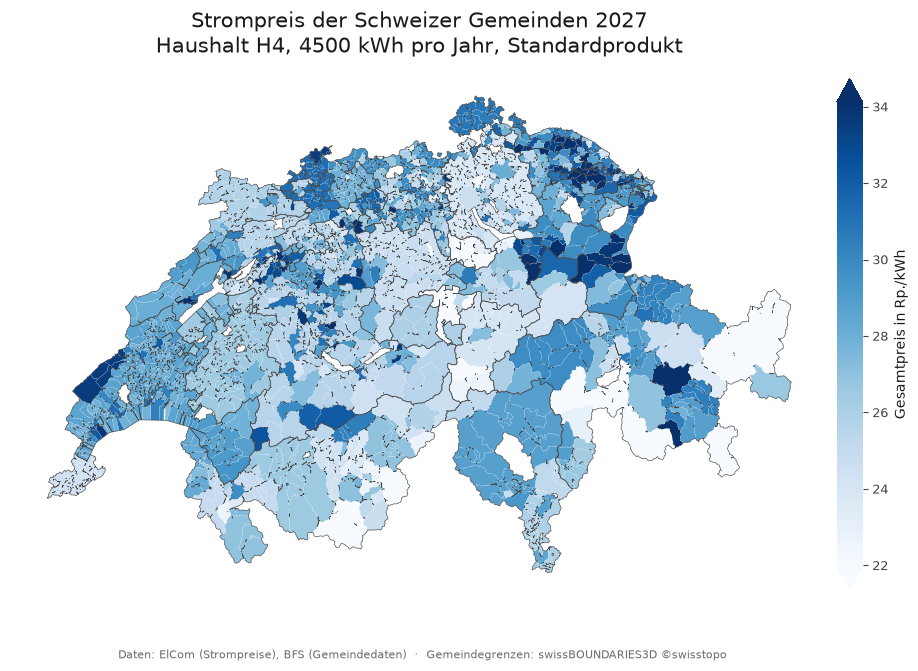

In [22]:
ABB = WURZEL / "abbildungen"
ABB.mkdir(exist_ok=True)
QUELLE = ("Daten: ElCom (Strompreise), BFS (Gemeindedaten)  ·  "
          "Gemeindegrenzen: swissBOUNDARIES3D ©swisstopo")

def zeichne(spalte, titel, cmap, norm, label, datei, extend="both"):
    fig, ax = plt.subplots(figsize=(11, 7.2))
    karte.plot(column=spalte, cmap=cmap, norm=norm, ax=ax,
               edgecolor="white", linewidth=0.08)
    kantone.boundary.plot(ax=ax, color="#444444", linewidth=0.45)
    ax.set_axis_off()
    ax.set_title(titel, fontsize=15, color="#1a1a1a", pad=14)

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    cb = fig.colorbar(sm, ax=ax, fraction=0.03, pad=0.01, extend=extend)
    cb.set_label(label, fontsize=10, color="#1a1a1a")
    cb.ax.tick_params(labelsize=9, colors="#444444")
    cb.outline.set_visible(False)

    fig.text(0.5, 0.045, QUELLE, ha="center", fontsize=8, color="#6b6b6b")
    fig.savefig(ABB / datei, dpi=300, bbox_inches="tight", facecolor="white")
    print(f"  {datei}  {(ABB / datei).stat().st_size/1e6:.2f} MB")
    return fig

# 93.8 Prozent der Gemeinden liegen zwischen 20 und 32 Rappen. Eine Skala, die bis
# zum Maximum von 45.9 reicht, draengt sie alle in zwei, drei kaum unterscheidbare
# Blautoene. Darum wird die Skala beim 2. und 98. Perzentil gekappt; die Pfeile an
# den Enden der Legende zeigen, dass es daneben noch Werte gibt.
unten, oben = karte.total_2027.quantile([0.02, 0.98])
print(f"Skala von {unten:.1f} bis {oben:.1f} Rp./kWh "
      f"(tatsaechliche Spanne {karte.total_2027.min():.1f} bis {karte.total_2027.max():.1f})")

fig1 = zeichne(
    "total_2027",
    "Strompreis der Schweizer Gemeinden 2027\nHaushalt H4, 4500 kWh pro Jahr, Standardprodukt",
    "Blues", mpl.colors.Normalize(unten, oben),
    "Gesamtpreis in Rp./kWh", "karte_preisniveau_2027.png")
plt.show()

Skala von -2.1 bis 14.7 Rp./kWh (Maximum 27.7, oben gekappt beim 98. Perzentil)


  karte_veraenderung_2021_2027.png  1.41 MB


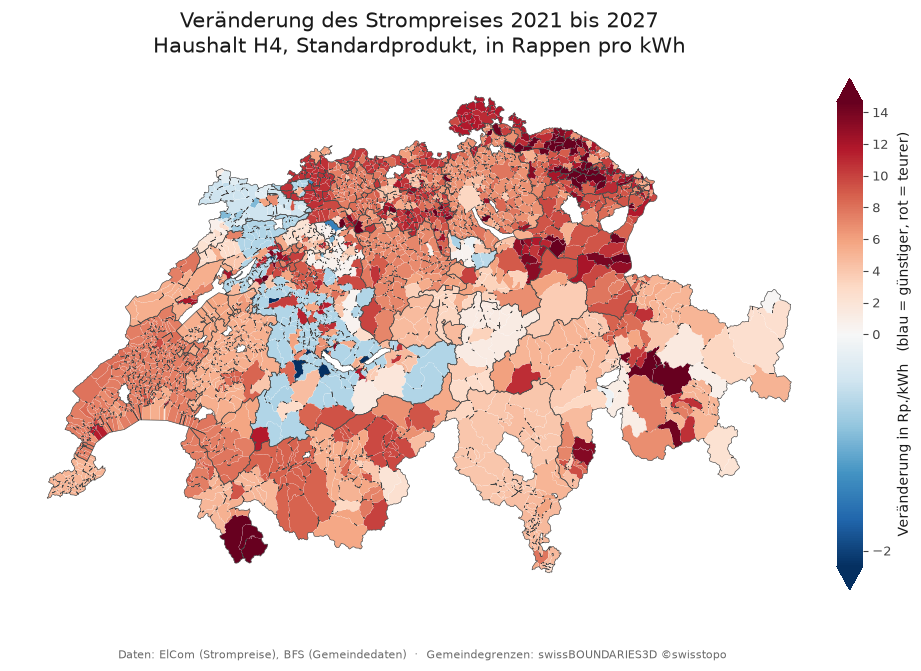


Gemeinden 2027 günstiger als 2021: 227 (10.9 %)


In [23]:
# Die Veraenderung reicht von -2.1 bis +27.7 Rappen. Eine symmetrische Skala von
# -27.7 bis +27.7 verschenkt die ganze blaue Haelfte: Die 227 guenstiger gewordenen
# Gemeinden waeren fast weiss und damit unsichtbar. Der Nullpunkt bleibt in der
# Mitte der Farbskala, die beiden Aeste sind aber unterschiedlich lang.
# Preis dafuer: Gleich kraeftiges Blau und Rot bedeuten NICHT gleich viele Rappen.
unten = karte.veraenderung.min()
oben = karte.veraenderung.quantile(0.98)
print(f"Skala von {unten:.1f} bis {oben:.1f} Rp./kWh "
      f"(Maximum {karte.veraenderung.max():.1f}, oben gekappt beim 98. Perzentil)")

fig2 = zeichne(
    "veraenderung",
    "Veränderung des Strompreises 2021 bis 2027\nHaushalt H4, Standardprodukt, in Rappen pro kWh",
    "RdBu_r", mpl.colors.TwoSlopeNorm(vmin=unten, vcenter=0, vmax=oben),
    "Veränderung in Rp./kWh   (blau = günstiger, rot = teurer)",
    "karte_veraenderung_2021_2027.png")
plt.show()

guenstiger = int((karte.veraenderung < 0).sum())
print(f"\nGemeinden 2027 günstiger als 2021: {guenstiger} "
      f"({guenstiger/len(karte)*100:.1f} %)")

### Interaktive Karten mit folium

Für die Erkundung und für das Video: anklickbar, mit Tooltip. Beim Darüberfahren
erscheinen Gemeinde, Kanton, Netzbetreiber und Preis – der Netzbetreiber bewusst
dabei, weil unsere Hypothese genau ihn betrifft.

**Die Karten werden geschrieben, aber nicht im Notebook angezeigt.** Eine
eingebettete folium-Karte mit 2087 Flächen bläht die Notebook-Datei um rund 2 MB
auf, und zwar bei jedem Durchlauf neu. Zu zweit wären das 4 MB pro Commit, für
Karten, die als eigene Dateien ohnehin im Repo liegen. Das verträgt sich schlecht
mit Git, siehe Abschnitt 10 der Projektanleitung.

Die fertigen Karten liegen unter `karten/` und werden im Browser geöffnet:

- `karten/karte_preisniveau_2027.html`
- `karten/karte_veraenderung_2021_2027.html`

In [24]:
import branca.colormap as cm
import folium

KARTEN = WURZEL / "karten"
KARTEN.mkdir(exist_ok=True)

def interaktiv(spalte, skala, titel, datei):
    m = folium.Map(location=[46.8, 8.23], zoom_start=8, tiles="cartodbpositron")
    werte = karte.set_index("gemeinde_nr")[spalte].to_dict()

    folium.GeoJson(
        karte[["gemeinde_nr", "gemeinde", "kanton", "netzbetreiber",
               spalte, "geometry"]],
        style_function=lambda f: {
            "fillColor": skala(werte.get(f["properties"]["gemeinde_nr"], 0)),
            "color": "white", "weight": 0.2, "fillOpacity": 0.85},
        highlight_function=lambda f: {"weight": 2, "color": "#1a1a1a"},
        tooltip=folium.GeoJsonTooltip(
            fields=["gemeinde", "kanton", "netzbetreiber", spalte],
            aliases=["Gemeinde", "Kanton", "Netzbetreiber", "Rp./kWh"],
            localize=True, sticky=False),
    ).add_to(m)

    skala.caption = titel
    skala.add_to(m)
    m.save(KARTEN / datei)
    print(f"  geschrieben: karten/{datei}  "
          f"({(KARTEN / datei).stat().st_size/1e6:.2f} MB) – im Browser öffnen")
    return m

skala_preis = cm.linear.Blues_09.scale(*karte.total_2027.quantile([0.02, 0.98]))
m1 = interaktiv("total_2027", skala_preis,
                "Strompreis 2027 in Rp./kWh (H4, Standardprodukt)",
                "karte_preisniveau_2027.html")

/Users/lennyfrei/Desktop/data-prices-electronic/.venv/lib/python3.11/site-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


  geschrieben: karten/karte_preisniveau_2027.html  (2.12 MB) – im Browser öffnen


In [25]:
skala_delta = cm.LinearColormap(
    ["#2166ac", "#f0f0f0", "#b2182b"],
    vmin=unten, vmax=oben, index=[unten, 0, oben])
m2 = interaktiv("veraenderung", skala_delta,
                "Veränderung 2021 bis 2027 in Rp./kWh (blau = günstiger)",
                "karte_veraenderung_2021_2027.html")

/Users/lennyfrei/Desktop/data-prices-electronic/.venv/lib/python3.11/site-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


  geschrieben: karten/karte_veraenderung_2021_2027.html  (2.14 MB) – im Browser öffnen


### Zeigt die Karte, was unsere Hypothese behauptet?

Abschnitt 5b der Projektanleitung sagt: Preise werden nicht von Gemeinden gesetzt,
sondern von Netzbetreibern. Wenn das stimmt, müssten die Farbgrenzen auf der Karte
den **Versorgungsgebieten** folgen und nicht den **Kantonsgrenzen**.

Das lässt sich messen statt nur anschauen. Für beide Einteilungen – Kanton und
Netzbetreiber – wird der Anteil der Preisstreuung berechnet, der *zwischen* den
Gruppen liegt. Je höher der Anteil, desto mehr erklärt die Einteilung.

In [26]:
def anteil_zwischen(werte, gruppen):
    """SS zwischen den Gruppen geteilt durch SS total, in Prozent."""
    gm = werte.mean()
    ss_total = ((werte - gm) ** 2).sum()
    ss_zw = werte.groupby(gruppen).apply(lambda g: len(g) * (g.mean() - gm) ** 2).sum()
    return ss_zw / ss_total * 100

zeilen = []
for jahr in ["total_2021", "total_2024", "total_2027"]:
    zeilen.append({
        "Jahr": jahr.replace("total_", ""),
        "Kanton": round(anteil_zwischen(karte[jahr], karte.kanton), 1),
        "Netzbetreiber": round(anteil_zwischen(karte[jahr], karte.netzbetreiber_id), 1),
        "Sprachregion": round(anteil_zwischen(karte[jahr], karte.sprachregion), 1),
    })
erklaert = pd.DataFrame(zeilen).set_index("Jahr")
print("Anteil der Preisstreuung, der zwischen den Gruppen liegt, in Prozent:")
erklaert

Anteil der Preisstreuung, der zwischen den Gruppen liegt, in Prozent:


,Kanton,Netzbetreiber,Sprachregion
Jahr,,,
2021,60.3,95.0,3.0
2024,23.1,94.0,1.7
2027,35.2,96.8,0.4


### Antwort: ja, man sieht es – mit einer Einschränkung

| Jahr | Kanton | **Netzbetreiber** | Sprachregion |
|---|---|---|---|
| 2021 | 60.3 % | **95.0 %** | 3.0 % |
| 2024 | 23.1 % | **94.0 %** | 1.7 % |
| 2027 | 35.2 % | **96.8 %** | 0.4 % |

Der Netzbetreiber erklärt in allen drei Jahren **94 bis 97 Prozent** der Streuung,
der Kanton je nach Jahr nur 23 bis 60 Prozent, die Sprachregion praktisch nichts.
Die Hypothese aus Abschnitt 5b der Projektanleitung wird damit gestützt.

**Was auf der Karte zu sehen ist.** Grosse zusammenhängende Flächen in genau
derselben Farbe, die über mehrere Dutzend Gemeinden reichen – das sind
Versorgungsgebiete einzelner Betreiber, nicht Kantone. Am deutlichsten auf der
Veränderungskarte: Der blaue Block rund um Zürich, Zug und den Aargau, wo die
Preise 2027 wieder unter dem Niveau von 2021 liegen, läuft quer über die
Kantonsgrenzen hinweg. Umgekehrt gibt es innerhalb einzelner Kantone kräftige
Unterschiede: Im Kanton Bern stehen tiefrote und hellblaue Gemeinden nebeneinander.

**Die Einschränkung, und sie ist wichtig.** Kanton und Netzbetreiber sind nicht
unabhängig voneinander. Viele grosse Versorger sind historisch kantonale Werke und
decken grosse Teile ihres Kantons ab. Genau deshalb erklärt der Kanton überhaupt 23
bis 60 Prozent – nicht weil die Kantonsgrenze den Preis bestimmt, sondern weil sie
oft mit einer Betreibergrenze zusammenfällt. Die Karte kann die beiden Erklärungen
nicht sauber trennen; sie zeigt nur, dass die Betreibergrenze die schärfere ist.

**Dass der Kantonsanteil 2024 auf 23 Prozent einbricht**, passt zur Geschichte in
Abschnitt 5: In jenem Jahr dominierte der Energieanteil die Unterschiede, und
Energie wird eingekauft, nicht von der Geografie bestimmt. Die Beschaffungsstrategie
schlägt die Lage.

**Ein Hinweis an Subraj zu Unterfrage 1 und Bonus 4.** Die Sprachregion erklärt
0.4 bis 3.0 Prozent der Streuung. Eine ANOVA über die Sprachregionen wird bei 2087
Gemeinden mit hoher Wahrscheinlichkeit ein signifikantes Ergebnis liefern – der
p-Wert misst aber nur, ob ein Unterschied existiert, nicht ob er zählt. Hier
zusätzlich die Effektstärke berichten, sonst steht im Bericht eine statistisch
signifikante Aussage über etwas, das praktisch bedeutungslos ist. Und die
Beobachtungen sind laut Abschnitt 5b ohnehin nicht unabhängig, die effektive
Fallzahl liegt bei rund 500.